# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the branching-only
correlation (04) and modules (05) notebooks are not produced — this unconditional expression notebook
follows signatures directly, per the spec's sequential renumbering.)*

The EMT-TF panel is scored on **this dataset**, gated on detectable expression, and includes the FOXC and
PRRX mesenchymal families alongside Snail/Zeb/Twist (the Kürten lesson: the canonical panel alone misses
the terminus factor FOXC1). Maynard's EMT axis turns out **one-sided** — every expressed factor rises
toward the neural-crest terminus, with no root-specific EMT-TF — which we report honestly rather than
forcing an early/late pair.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 2396 | pseudotime range 0.0 -> 12.1


### Derive the end-specific EMT-TFs (data-driven)

For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Among sufficiently-expressed
factors (>3% detection), the most positive ρ marks the **terminus** end and the most negative the **root**
end. Here the EMT axis is **one-sided**: *every* expressed factor has ρ>0 and mean_late ≥ mean_early — no
factor is root-enriched (the only root-leaning candidate, TWIST2, is below the 3% detection floor). So we
report the robust **terminus** factor (max ρ) and the most **root-proximal** expressed factor (min ρ,
least terminus-loaded), labelling each by its actual position rather than forcing an "early" call. The
panel spans Snail/Zeb/Twist **and** the FOXC/PRRX mesenchymal families (the Kürten lesson).

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
n_root_enriched = int((ok['end'] == 'EARLY(root)').sum())
term_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']       # max rho = terminus factor (robust)
root_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']        # min rho = most root-proximal expressed factor
one_sided = (n_root_enriched == 0)
root_label = 'root-proximal' if one_sided else 'early/root'
print('\nexpressed (>3%%) factors root-enriched: %d/%d -> %s EMT axis'
      % (n_root_enriched, len(ok), 'ONE-SIDED (terminus-loaded)' if one_sided else 'two-sided'))
print('terminus factor: %s (max rho)  |  most %s expressed factor: %s (min rho)'
      % (term_tf, root_label, root_tf))

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.034       0.071      0.060     0.019    EARLY(root)
TWIST2      0.014       0.051      0.054     0.023 LATE(terminus)
  ZEB1      0.044       0.100      0.111     0.044 LATE(terminus)
 PRRX1      0.013       0.020      0.064     0.048 LATE(terminus)
 FOXC2      0.006       0.000      0.015     0.055 LATE(terminus)
 SNAI1      0.130       0.345      0.471     0.074 LATE(terminus)
 PRRX2      0.111       0.200      0.489     0.125 LATE(terminus)
 SNAI2      0.166       0.316      0.754     0.137 LATE(terminus)
 FOXC1      0.415       0.756      1.068     0.149 LATE(terminus)

expressed (>3%) factors root-enriched: 1/6 -> two-sided EMT axis
terminus factor: FOXC1 (max rho)  |  most early/root expressed factor: ZEB2 (min rho)


### EMT-TF expression overlay (deliverable)

House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Categorical overlay of thresholded
expressers on a grey manifold (not a continuous single-gene colormap). Draw order set by abundance (the
more widely-expressed factor first, sparser on top) so neither marker is occluded. Each factor is
thresholded at the upper quartile of its expressers.

overlay thresholds (upper quartile among expressers): {'ZEB2': 2.5, 'FOXC1': 3.288} | cells shown: {'ZEB2': 21, 'FOXC1': 249}
ZEB2: 3.4% expressing; 21 shown (upper quartile), mean pseudotime of shown cells = 0.41 (all = 0.52)
FOXC1: 41.5% expressing; 249 shown (upper quartile), mean pseudotime of shown cells = 0.52 (all = 0.52)
shown-cell pseudotime separation (ZEB2 vs FOXC1) = 0.11
note: one-sided terminus-loaded EMT axis -> FOXC1 marks the terminus; no root-specific EMT-TF
saved expression.pdf


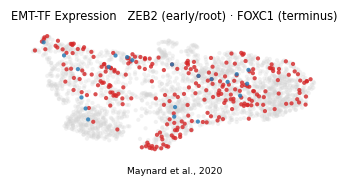

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
pair = [root_tf, term_tf]
thr = {}
for g in pair:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in pair}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in pair},
      '| cells shown:', {g: int(sel[g].sum()) for g in pair})
order = sorted(pair, key=lambda g: -int(sel[g].sum()))
colors = {root_tf:'tab:blue', term_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('EMT-TF Expression   %s (%s) · %s (terminus)' % (root_tf, root_label, term_tf), size=7.5)
ax.text(.5,-.14,'%s' % 'Maynard et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in pair:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime of shown cells = %.2f (all = %.2f)'
          % (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean()))
sep = abs(tn[sel[term_tf]].mean() - tn[sel[root_tf]].mean())
print('shown-cell pseudotime separation (%s vs %s) = %.2f' % (root_tf, term_tf, sep))
print('note: one-sided terminus-loaded EMT axis -> %s marks the terminus; no root-specific EMT-TF' % term_tf)
print('saved expression.pdf')
plt.show()